In [1]:
from pathlib import Path
import ast
import json
import numpy as np
import matplotlib.pyplot as plt
import torch
import soundfile as sf
from torchaudio.functional import melscale_fbanks, lfilter

DATA = Path("/media/ensound/Ventoy/apnea_data")
FIGURES = Path("./figures")
FIGURES.mkdir(exist_ok=True)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

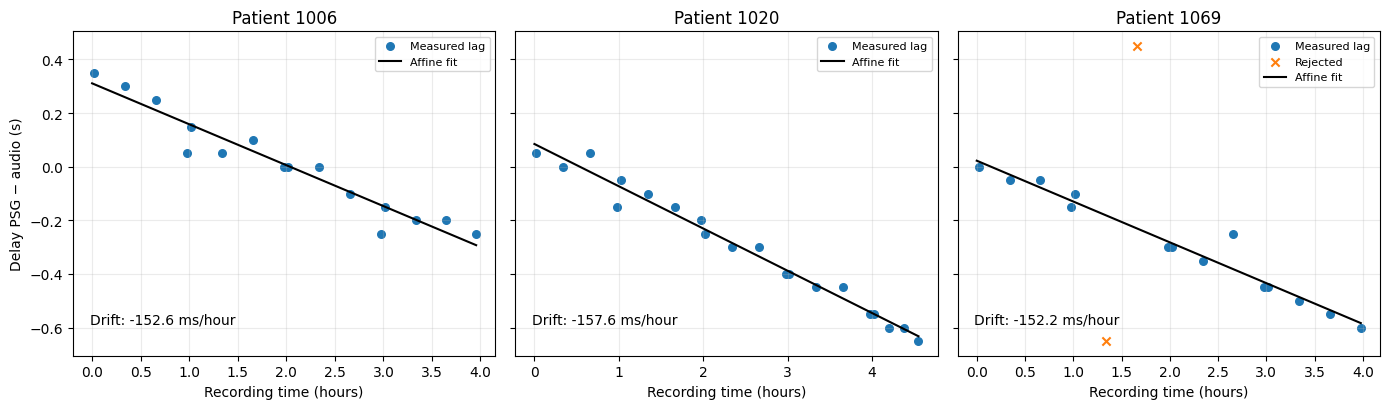

In [3]:
patients = ("1006", "1020", "1069")
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2), sharey=True)

for ax, patient in zip(axes, patients):
    fit = json.loads((DATA / "alignment" / patient / f"{patient}.json").read_text())
    points = np.array(fit["points"])
    good = np.array(fit["inlier_mask"], dtype=bool)
    time, lag = points[:, 0], points[:, 1]

    ax.scatter(time[good] / 3600, lag[good], s=30, label="Measured lag")
    if (~good).any():
        ax.scatter(time[~good] / 3600, lag[~good], s=35,
                   marker="x", color="tab:orange", label="Rejected")
    line = np.array([0, time.max()])
    ax.plot(line / 3600, (fit["a"] - 1) * line + fit["b"],
            color="black", linewidth=1.5, label="Affine fit")
    ax.set_title(f"Patient {patient}")
    ax.set_xlabel("Recording time (hours)")
    ax.grid(alpha=0.25)
    ax.text(0.04, 0.1, f"Drift: {(fit['a'] - 1) * 3600000:.1f} ms/hour",
            transform=ax.transAxes, fontsize=10)
    ax.legend(fontsize=8)

axes[0].set_ylabel("Delay PSG − audio (s)")
fig.tight_layout()
fig.savefig(FIGURES / "alignment_lag.png", dpi=200)
plt.show()


In [4]:

WINDOW, CONTEXT = 60, 600 #s
STFT_WINDOW, STFT_HOP = 40, 10 #ms
MEL_BANDS = 128 
N_FFT = round(STFT_WINDOW * 48000 / 1000)
HOP = round(STFT_HOP * 48000 / 1000)

PATIENT, START, DURATION = "1010", 1100, 60
path = DATA / "audio" / PATIENT / f"{PATIENT}[001].wav"

with sf.SoundFile(path) as f:
    assert f.samplerate == 48000
    f.seek(int(START * 48000))
    audio = f.read(int(DURATION * 48000), dtype="float32")


hann = torch.hann_window(N_FFT, device=DEVICE)
mel_filters = melscale_fbanks(N_FFT // 2 + 1, 0, 24000, MEL_BANDS, 48000, norm="slaney", mel_scale="slaney").T.to(DEVICE)

with torch.inference_mode():
    audio = torch.as_tensor(audio, dtype=torch.float32, device=DEVICE)
    spec = torch.stft(audio, n_fft=N_FFT, hop_length=HOP, window=hann, 
                            center=True, pad_mode="reflect", return_complex=True).abs()[:, :-1]
    mel_spec = (mel_filters @ spec)
    a = torch.tensor([1, -0.975], dtype=torch.float32, device=DEVICE)
    b = torch.tensor([0.025, 0], dtype=torch.float32, device=DEVICE)
    smooth = lfilter(mel_spec, a, b, clamp=False)
    decay = (0.975 ** torch.arange(1, DURATION*100+1, dtype=torch.float64, device=DEVICE)).float()
    smooth += mel_spec[:, :1] * decay
    pcen_spec = torch.sqrt(mel_spec / (1e-6 + smooth).pow(0.98) + 2) - np.sqrt(2)

    spec= spec.cpu().numpy()
    mel_spec= mel_spec.cpu().numpy()
    pcen_spec = pcen_spec.cpu().numpy()

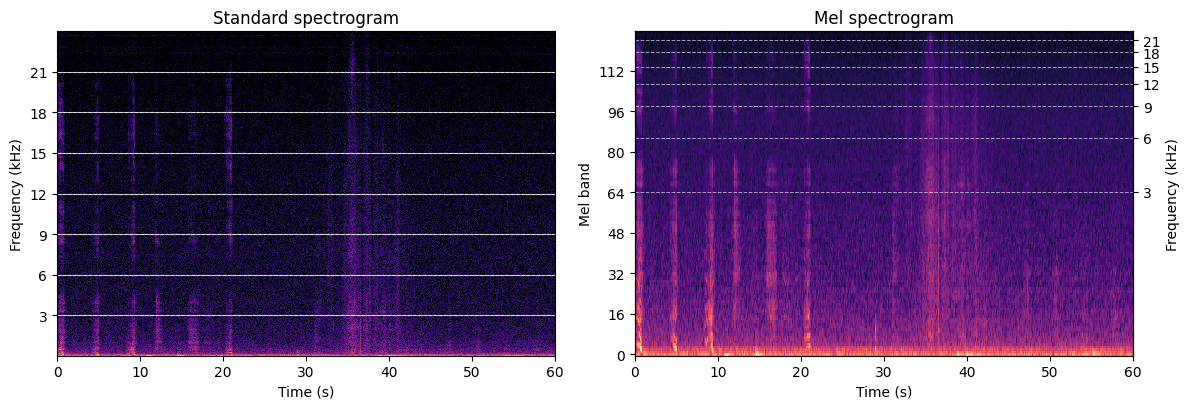

In [5]:

def log_mag(values):
    return 20 * np.log10(np.maximum(values / max(values.max(), 1e-12), 1e-4))

def hz_to_mel(f):
    return np.where(f < 1000, f / (200 / 3), 15 + np.log(np.maximum(f, 1) / 1000) / (np.log(6.4) / 27))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharex=True)
axes[0].imshow(log_mag(spec), origin="lower", aspect="auto",
            extent=[0, DURATION, 0, 24000],
            cmap="magma", interpolation="nearest")
axes[0].grid(axis="y")
axes[1].imshow(log_mag(mel_spec), origin="lower", aspect="auto",
            extent=[0, DURATION, -0.5, MEL_BANDS - 0.5],
            cmap="magma", interpolation="nearest")

freqs = np.arange(3000, 24000, 3000)
mel_y = (MEL_BANDS + 1) * hz_to_mel(freqs) / hz_to_mel(24000) - 1
bands = np.arange(0, MEL_BANDS, 16)

for f, y in zip(freqs, mel_y):
    axes[0].axhline(f, color="white", alpha=0.6, linestyle="--", linewidth=0.7)
    axes[1].axhline(y, color="white", alpha=0.6, linestyle="--", linewidth=0.7)

axes[0].set_title("Standard spectrogram")
axes[0].set_yticks(freqs, [f"{f/1000:g}" for f in freqs])
axes[0].set_ylabel("Frequency (kHz)")
axes[0].set_xlabel("Time (s)")
axes[1].set_title("Mel spectrogram")
axes[1].set_yticks(np.arange(0, MEL_BANDS, 16))
axes[1].set_ylabel("Mel band")
axes[1].set_xlabel("Time (s)")
ax_freq = axes[1].twinx()
ax_freq.set_ylim(axes[1].get_ylim())
ax_freq.set_yticks(mel_y, [f"{f/1000:g}" for f in freqs])
ax_freq.set_ylabel("Frequency (kHz)")

fig.tight_layout()
plt.savefig(FIGURES / "mel_comparison.png")
plt.show()

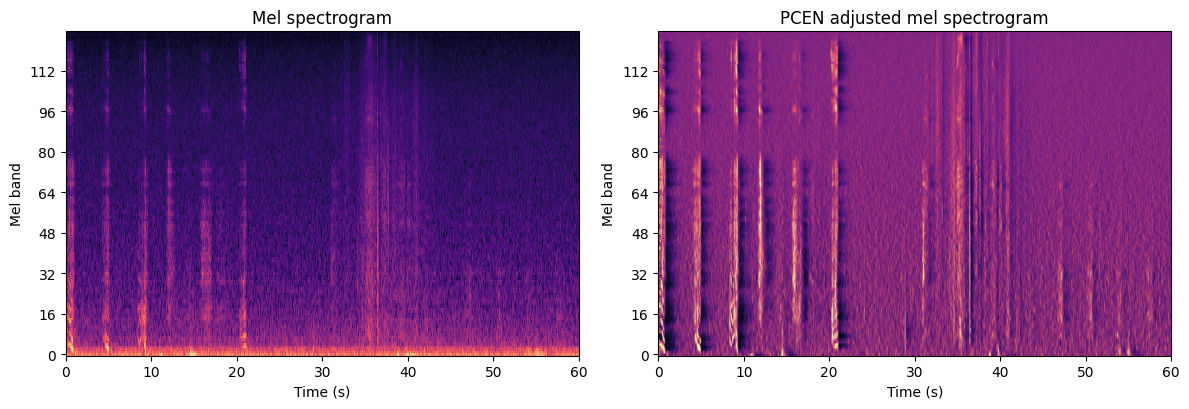

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharex=True)
axes[0].imshow(log_mag(mel_spec), origin="lower", aspect="auto",
            extent=[0, DURATION, -0.5, MEL_BANDS - 0.5],
            cmap="magma", interpolation="nearest")
im = axes[1].imshow(pcen_spec, origin="lower", aspect="auto",
    extent=[0, DURATION, -0.5, MEL_BANDS - 0.5],
    cmap="magma", vmin=0, vmax=np.quantile(pcen_spec, 0.995))

bands = np.arange(0, MEL_BANDS, 16)
axes[0].set_title("Mel spectrogram")
axes[0].set_yticks(np.arange(0, MEL_BANDS, 16))
axes[0].set_ylabel("Mel band")
axes[0].set_xlabel("Time (s)")
axes[1].set_title("PCEN adjusted mel spectrogram")
axes[1].set_yticks(np.arange(0, MEL_BANDS, 16))
axes[1].set_ylabel("Mel band")
axes[1].set_xlabel("Time (s)")

fig.tight_layout()
plt.savefig(FIGURES / "pcen_comparison.png")
plt.show()

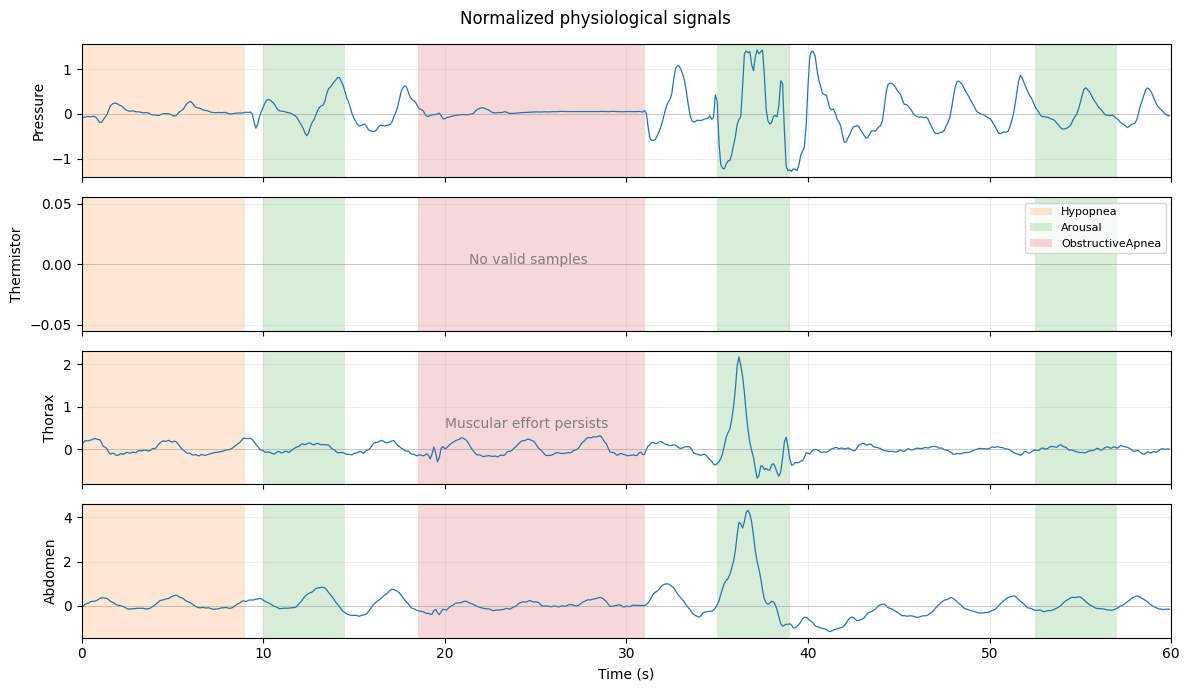

In [7]:
# Load only the preprocessing definitions and parameters, not the generation loop.
path = Path("2_preprocessing.ipynb")
if not path.exists():
    path = Path("final/2_preprocessing.ipynb")
preprocessing = json.loads(path.read_text())
prepare = {}
functions = {"load_signals", "load_masks", "correct_pressure_polarity",
             "normalize_targets", "prepare_signals"}
parameters = {"DATA", "names", "labels", "WINDOW", "CONTEXT"}
for cell in preprocessing["cells"]:
    if cell["cell_type"] != "code":
        continue
    for node in ast.parse("".join(cell["source"])).body:
        if (isinstance(node, (ast.Import, ast.ImportFrom))
            or isinstance(node, ast.FunctionDef) and node.name in functions
            or isinstance(node, ast.Assign) and any(
                isinstance(item, ast.Name) and item.id in parameters
                for target in node.targets for item in ast.walk(target))):
            exec(compile(ast.Module(body=[node], type_ignores=[]), str(path), "exec"), prepare)

prepare["DATA"] = DATA
signals, valid = prepare["prepare_signals"](PATIENT)
a, b = round(START * 10), round((START + DURATION) * 10)
assert 0 <= a < b <= len(signals), "Window outside physiological recording"
time = np.arange(b - a) / 10

fig, axes = plt.subplots(4, 1, figsize=(12, 7), sharex=True)
for c, (ax, name) in enumerate(zip(axes, ["Pressure", "Thermistor", "Thorax", "Abdomen"])):
    ax.plot(time, np.where(valid[a:b, c], signals[a:b, c], np.nan), linewidth=0.9)
    if not valid[a:b, c].any():
        ax.text(0.41, 0.5, "No valid samples",
                transform=ax.transAxes, ha="center", color="gray")
    ax.axhline(0, color="gray", linewidth=0.5, alpha=0.5)
    ax.set_ylabel(name)
    ax.grid(alpha=0.2)

colors = {"ObstructiveApnea": "tab:red", "CentralApnea": "tab:blue",
          "MixedApnea": "tab:purple", "Hypopnea": "tab:orange", "Arousal": "tab:green"}
root = prepare["ET"].parse(DATA / "annotations" / f"{PATIENT}.rml").getroot()
for event in root.iter():
    kind = event.get("Type", "")
    if kind not in colors:
        continue
    start = float(event.get("Start"))
    end = start + float(event.get("Duration"))
    if start < START + DURATION and end > START:
        for ax in axes:
            ax.axvspan(max(start, START) - START, min(end, START + DURATION) - START,
                       color=colors[kind], alpha=0.18, linewidth=0, label=kind)

handles, labels = axes[0].get_legend_handles_labels()
legend = dict(zip(labels, handles))
if legend:
    axes[1].legend(legend.values(), legend.keys(), loc="upper right", fontsize=8)
axes[-1].set_xlabel("Time (s)")
axes[-1].set_xlim(0, DURATION)

axes[2].text(20, 0.5, "Muscular effort persists", color="gray")

fig.suptitle(f"Normalized physiological signals")
fig.tight_layout()
fig.savefig(FIGURES / "physiological_signals.png", dpi=200)
plt.show()


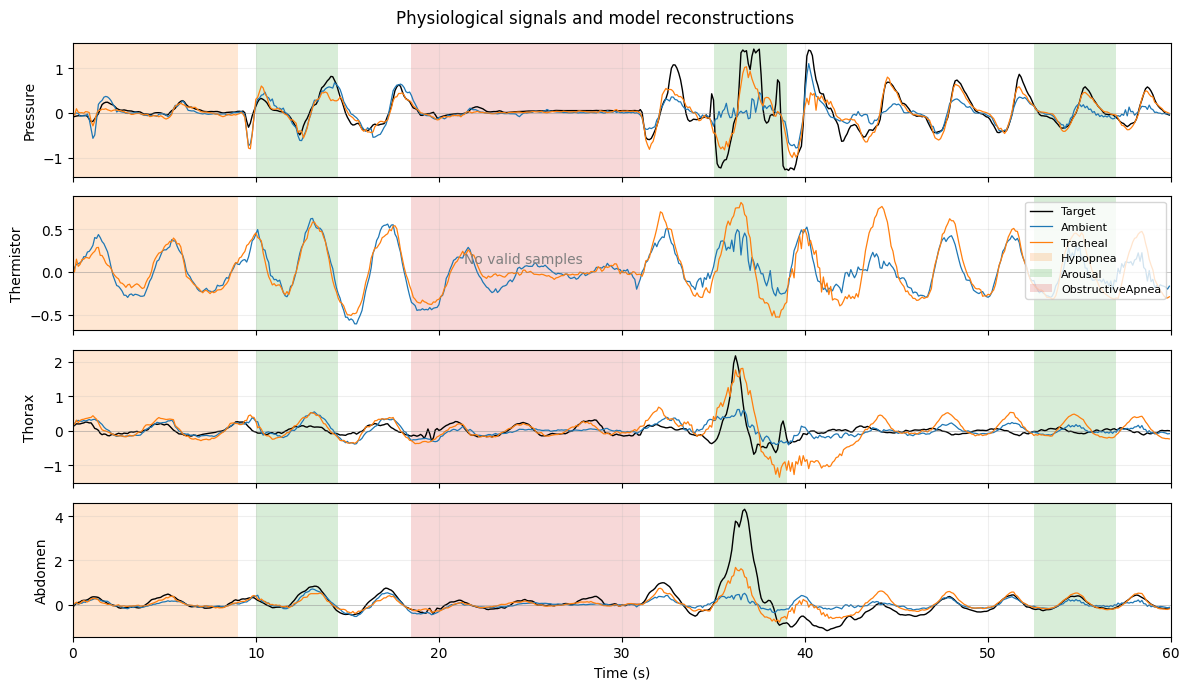

In [8]:
# Compare the real targets with both selected regression models.
import importlib.util

OUTPUT = Path("../output")
snapshot = OUTPUT / "full_residual_261_splits2027_2028/candidate_model.py"
specification = importlib.util.spec_from_file_location("trained_model", snapshot)
trained_model = importlib.util.module_from_spec(specification)
specification.loader.exec_module(trained_model)
assert DURATION == 60, "The models were trained on 60-second windows"
from fractions import Fraction
from scipy.signal import firwin, resample_poly


def read_audio_window(channel):
    folder = DATA / channel / PATIENT
    segments = json.loads((folder / "metadata.json").read_text())["segments"]
    fit = json.loads((DATA / "alignment" / PATIENT / f"{PATIENT}.json").read_text())
    ratio = Fraction(fit["a"]).limit_denominator(100000)
    up, down = ratio.numerator, ratio.denominator
    shift = round(fit["b"] * 48000)
    count, q = round(DURATION * 48000), round(START * 48000) - shift
    offsets = np.r_[0, np.cumsum([segment["count"] for segment in segments])]
    end = max(offsets[i] + segment["end_valid"]
              for i, segment in enumerate(segments) if segment["end_valid"] > 0)
    assert q >= 0 and q + count <= (end * up + down - 1) // down, "Window outside valid audio"
    # Preserve the resampling phase, reading only this window and filter margins.
    left = max(0, int(np.floor((q * down / up - 32) / down)) * down)
    right = min(end, int(np.ceil((q + count) * down / up)) + 32)
    audio = np.zeros(right - left, dtype=np.float32)
    for i, segment in enumerate(segments):
        lo, hi = max(left, offsets[i]), min(right, offsets[i + 1])
        if hi > lo:
            with sf.SoundFile(folder / segment["file"]) as reader:
                assert reader.samplerate == 48000
                reader.seek(int(lo - offsets[i]))
                audio[lo-left:hi-left] = reader.read(int(hi-lo), dtype="float32")
    if up != down:
        kernel = firwin(20 * max(up, down) + 1, 1 / max(up, down), window=("kaiser", 5)).astype(np.float32)
        audio = resample_poly(audio, up, down, window=kernel)
    first = q - left // down * up
    return audio[first:first + count]


# Reuse the exact PCEN definition from preprocessing.
for cell in preprocessing["cells"]:
    if cell["cell_type"] == "code":
        for node in ast.parse("".join(cell["source"])).body:
            if isinstance(node, ast.FunctionDef) and node.name == "make_pcen_image":
                exec(compile(ast.Module(body=[node], type_ignores=[]), "PCEN", "exec"), prepare)
prepare.update(DEVICE=DEVICE, N_FFT=N_FFT, HOP=HOP, hann=hann, mel_filters=mel_filters)
a, b = round(START * 10), round((START + DURATION) * 10)
target, mask = signals[a:b], valid[a:b]
assert len(target) == 600, "Window outside physiological recording"
time = np.arange(len(target)) / 10
reconstructed = {}
for name, run, channel in [("Ambient", "full_residual_261_2027", "audio"),
                           ("Tracheal", "tracheal_261_2027", "audio_tracheal")]:
    model = trained_model.Model().to(DEVICE).eval()
    regression = torch.nn.Sequential(model.backbone, model.regression_head)
    checkpoint = torch.load(OUTPUT / run / "reconstruction/candidate/best.pt",
                            map_location=DEVICE, weights_only=False)
    model.backbone.load_state_dict({k.removeprefix("backbone."): v for k, v in checkpoint["model"].items() if k.startswith("backbone.")})
    model.regression_head.load_state_dict({k.removeprefix("regression_head."): v for k, v in checkpoint["model"].items() if k.startswith("regression_head.")})
    audio_window = read_audio_window(channel)
    assert len(audio_window) == round(DURATION * 48000), "Incomplete audio window"
    image = prepare["make_pcen_image"](audio_window)
    image = torch.as_tensor(image.astype(np.float32), device=DEVICE)[None, None]
    with torch.inference_mode(), torch.autocast(DEVICE, dtype=torch.bfloat16, enabled=DEVICE == "cuda"):
        reconstructed[name] = regression(image)[0].float().cpu().numpy().T
    del model, regression, checkpoint

fig, axes = plt.subplots(4, 1, figsize=(12, 7), sharex=True)
for c, (ax, name) in enumerate(zip(axes, ["Pressure", "Thermistor", "Thorax", "Abdomen"])):
    ax.plot(time, np.where(mask[:, c], target[:, c], np.nan), color="black", linewidth=1, label="Target")
    for microphone, color in [("Ambient", "tab:blue"), ("Tracheal", "tab:orange")]:
        ax.plot(time, reconstructed[microphone][:, c], color=color, linewidth=0.9, label=microphone)
    if not mask[:, c].any():
        ax.text(0.41, 0.5, "No valid samples",
                transform=ax.transAxes, ha="center", color="gray")
    ax.axhline(0, color="gray", linewidth=0.5, alpha=0.5)
    ax.set_ylabel(name)
    ax.grid(alpha=0.2)

colors = {"ObstructiveApnea": "tab:red", "CentralApnea": "tab:blue",
          "MixedApnea": "tab:purple", "Hypopnea": "tab:orange", "Arousal": "tab:green"}
root = prepare["ET"].parse(DATA / "annotations" / f"{PATIENT}.rml").getroot()
for event in root.iter():
    kind = event.get("Type", "")
    if kind not in colors:
        continue
    start = float(event.get("Start"))
    end = start + float(event.get("Duration"))
    if start < START + DURATION and end > START:
        for ax in axes:
            ax.axvspan(max(start, START) - START, min(end, START + DURATION) - START,
                       color=colors[kind], alpha=0.18, linewidth=0, label=kind)

handles, labels = axes[0].get_legend_handles_labels()
legend = dict(zip(labels, handles))
if legend:
    axes[1].legend(legend.values(), legend.keys(), loc="upper right", fontsize=8)
axes[-1].set_xlabel("Time (s)")
axes[-1].set_xlim(0, DURATION)



fig.suptitle(f"Physiological signals and model reconstructions")
fig.tight_layout()
fig.savefig(FIGURES / "physiological_reconstruction.png", dpi=200)
plt.show()


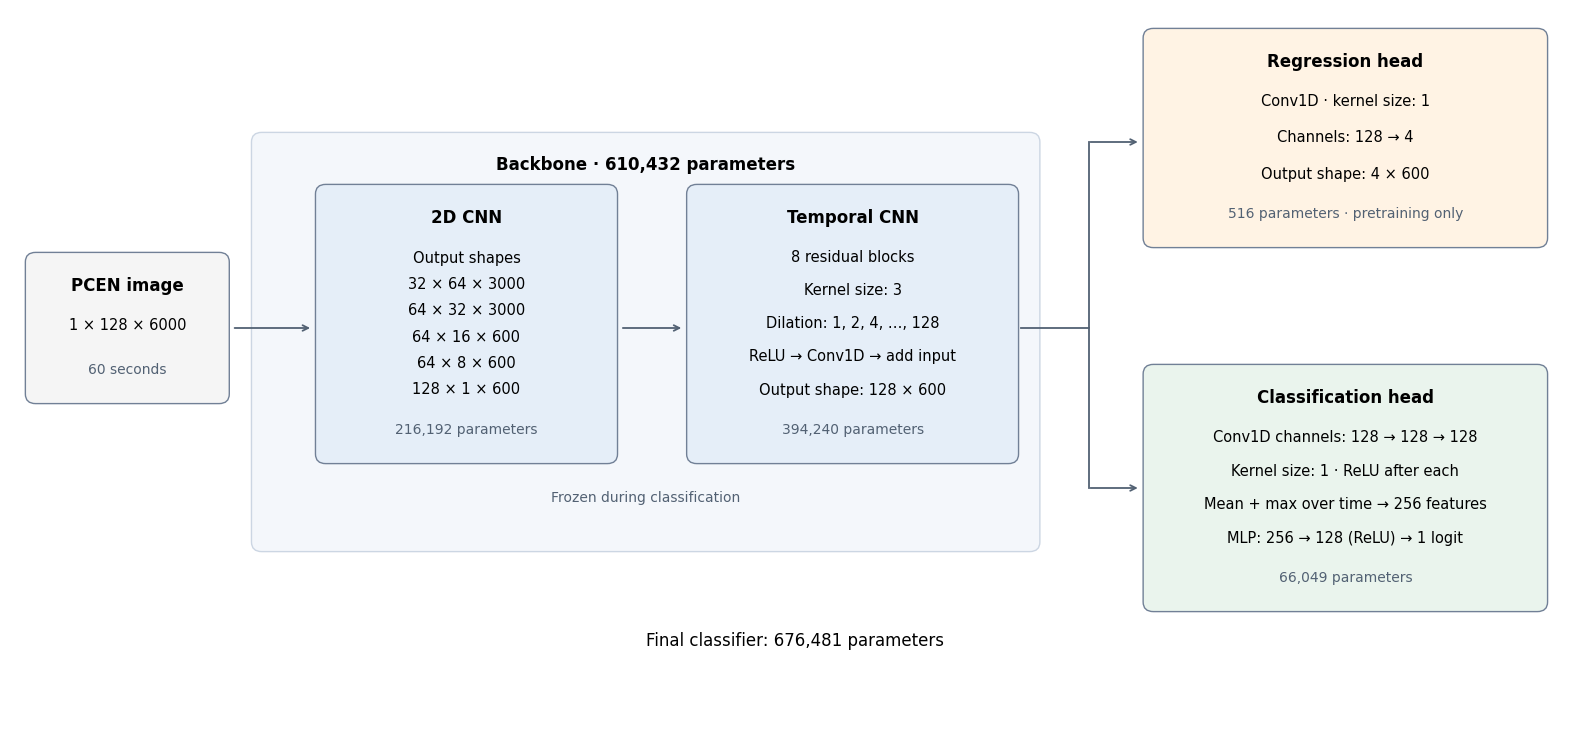

In [15]:
# Clear architecture overview; keep the previous diagram as a backup.
from matplotlib.patches import FancyBboxPatch
from model import Model

model = Model()
count = lambda module: sum(p.numel() for p in module.parameters())
fig, ax = plt.subplots(figsize=(16, 7.5))
ax.set(xlim=(0, 18.4), ylim=(0.5, 9.5))
ax.axis("off")


def box(x, y, w, h, title, lines, footer, color):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.12",
                               facecolor=color, edgecolor="#718096", linewidth=1))
    ax.text(x+w/2, y+h-0.3, title, ha="center", va="center", fontsize=12, weight="bold")
    for position, line in zip(np.linspace(y+h-0.8, y+0.8, len(lines)), lines):
        ax.text(x+w/2, position, line, ha="center", va="center", fontsize=10.5)
    ax.text(x+w/2, y+0.3, footer, ha="center", va="center", fontsize=10, color="#526173")


def arrow(start, end):
    ax.annotate("", xy=end, xytext=start,
                arrowprops=dict(arrowstyle="->", color="#526173", linewidth=1.3))


ax.add_patch(FancyBboxPatch((2.95, 2.85), 9, 5, boxstyle="round,pad=0.12",
                           facecolor="#F4F7FB", edgecolor="#CCD6E3"))
ax.text(7.45, 7.5, f"Backbone · {count(model.backbone):,} parameters",
        ha="center", fontsize=12, weight="bold")
ax.text(7.45, 3.35, "Frozen during classification", ha="center", fontsize=10, color="#526173")

box(0.3, 4.7, 2.15, 1.65, "PCEN image", ["1 × 128 × 6000"],
    "60 seconds", "#F5F5F5")
box(3.7, 3.95, 3.3, 3.25, "2D CNN",
    ["Output shapes", "32 × 64 × 3000", "64 × 32 × 3000",
     "64 × 16 × 600", "64 × 8 × 600", "128 × 1 × 600"],
    f"{count(model.backbone.cnn):,} parameters", "#E5EEF8")
box(8.05, 3.95, 3.65, 3.25, "Temporal CNN",
    ["8 residual blocks", "Kernel size: 3", "Dilation: 1, 2, 4, …, 128",
     "ReLU → Conv1D → add input", "Output shape: 128 × 600"],
    f"{count(model.backbone.tcn):,} parameters", "#E5EEF8")
box(13.4, 6.65, 4.5, 2.5, "Regression head",
    ["Conv1D · kernel size: 1", "Channels: 128 → 4", "Output shape: 4 × 600"],
    f"{count(model.regression_head):,} parameters · pretraining only", "#FFF3E4")
box(13.4, 2.1, 4.5, 2.85, "Classification head",
    ["Conv1D channels: 128 → 128 → 128", "Kernel size: 1 · ReLU after each",
     "Mean + max over time → 256 features", "MLP: 256 → 128 (ReLU) → 1 logit"],
    f"{count(model.classification_head):,} parameters", "#EAF4ED")

arrow((2.6, 5.525), (3.55, 5.525))
arrow((7.15, 5.525), (7.9, 5.525))
ax.plot([11.85, 12.65, 12.65], [5.525, 5.525, 7.85], color="#526173", linewidth=1.3)
ax.plot([12.65, 12.65], [5.525, 3.525], color="#526173", linewidth=1.3)
arrow((12.63, 7.85), (13.25, 7.85))
arrow((12.63, 3.525), (13.25, 3.525))
ax.text(9.2, 1.55, f"Final classifier: {count(model.backbone) + count(model.classification_head):,} parameters",
        ha="center", fontsize=12)

fig.tight_layout()
fig.savefig(FIGURES / "architecture_clear.png", dpi=200, bbox_inches="tight", facecolor="white")
plt.show()


In [ ]:
SEED = 2027
runs = {"Ambient": Path("training"), "Tracheal": Path("training_tracheal")}
fig, ax = plt.subplots(figsize=(8, 4.2))

for (name, run), color in zip(runs.items(), ["tab:blue", "tab:orange"]):
    history = json.loads((run / f"split{SEED}" / "frozen_backbone/regression/history.json").read_text())
    epochs = [row["epoch"] for row in history]
    training = [row for j, row in enumerate(history)
                if row["epoch"] - (history[j-1]["epoch"] if j else 0) > 0.1]
    ax.plot([row["epoch"] for row in training], [row["train_loss"] for row in training],
            color=color, linestyle="--", label=f"{name}: training")
    ax.plot(epochs, [row["validation"]["loss"] for row in history],
            color=color, label=f"{name}: validation")
    selected = min(history, key=lambda row: row["validation"]["loss"])
    ax.plot(selected["epoch"], selected["validation"]["loss"],
            marker="*", markersize=10, color=color, markeredgecolor="black", linestyle="none", zorder=2)

ax.set_xlabel("Epoch")
ax.set_ylabel("Patient-balanced loss")
ax.grid(alpha=0.25)
ax.legend(fontsize=9)
fig.tight_layout()
fig.savefig(FIGURES / "reconstruction_loss.png", dpi=200, bbox_inches="tight")
plt.show()


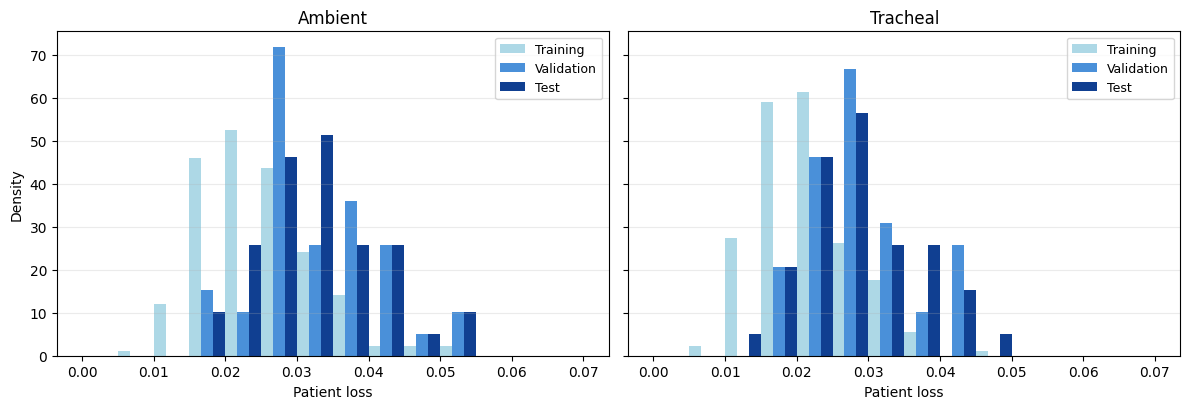

In [3]:
SEED = 2027
runs = {"Ambient": Path("training"), "Tracheal": Path("training_tracheal")}
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharex=True, sharey=True)
bins = np.linspace(0, 0.07, 15)

for ax, (name, run) in zip(axes, runs.items()):
    results = json.loads((run / f"split{SEED}" / "frozen_backbone/results.json").read_text())["regression"]
    losses = [[np.mean([channel["huber"] for channel in patient.values() if channel is not None])
               for patient in results[part]["patients"].values()]
              for part in ["train", "validation", "test"]]
    ax.hist(losses, bins=bins, density=True, rwidth=1,
            color=["#ADD8E6", "#4A90D9", "#103F91"],
            label=["Training", "Validation", "Test"])
    ax.set_title(name)
    ax.set_xlabel("Patient loss")
    ax.grid(axis="y", alpha=0.25)
    ax.legend(fontsize=9)

axes[0].set_ylabel("Density")
fig.tight_layout()
fig.savefig(FIGURES / "reconstruction_loss_distributions.png", dpi=200, bbox_inches="tight")
plt.show()


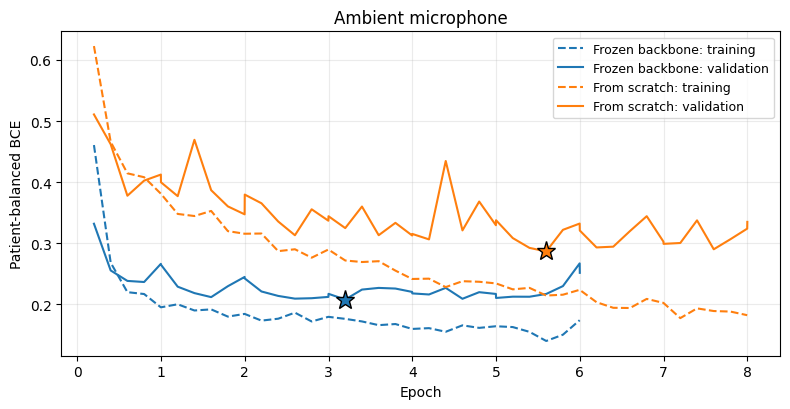

In [6]:
SEED = 2027
OUTPUT = Path("training") / f"split{SEED}"
runs = {"Frozen backbone": "frozen_backbone", "From scratch": "from_scratch"}
fig, ax = plt.subplots(figsize=(8, 4.2))

for (name, run), color in zip(runs.items(), ["tab:blue", "tab:orange"]):
    history = json.loads((OUTPUT / run / "classification/history.json").read_text())
    epochs = [row["epoch"] for row in history]
    training = [row for j, row in enumerate(history)
                if row["epoch"] - (history[j-1]["epoch"] if j else 0) > 0.1]
    ax.plot([row["epoch"] for row in training], [row["train_loss"] for row in training],
            color=color, linestyle="--", label=f"{name}: training")
    ax.plot(epochs, [row["validation"]["loss"] for row in history],
            color=color, label=f"{name}: validation")
    selected = min(history, key=lambda row: row["validation"]["loss"])
    ax.plot(selected["epoch"], selected["validation"]["loss"],
            marker="*", markersize=14, color=color, markeredgecolor="black", linestyle="none", zorder=5)

ax.set_title("Ambient microphone")
ax.set_xlabel("Epoch")
ax.set_ylabel("Patient-balanced BCE")
ax.grid(alpha=0.25)
ax.legend(fontsize=9)
fig.tight_layout()
fig.savefig(FIGURES / "classification_loss_ambient.png", dpi=200, bbox_inches="tight")
plt.show()


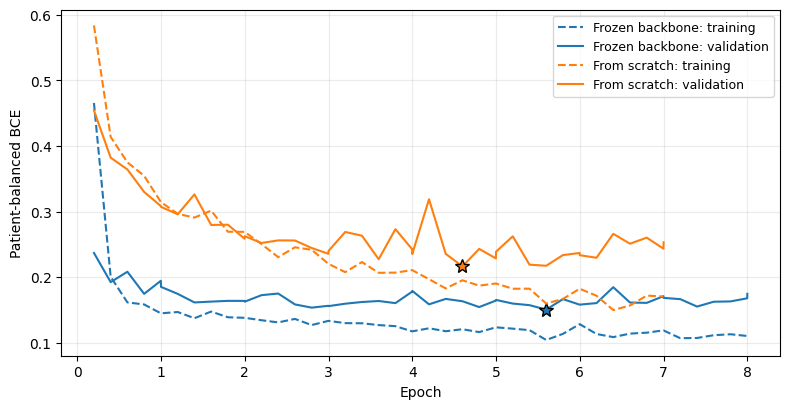

In [8]:
SEED = 2027
OUTPUT = Path("training_tracheal") / f"split{SEED}"
runs = {"Frozen backbone": "frozen_backbone", "From scratch": "from_scratch"}
fig, ax = plt.subplots(figsize=(8, 4.2))

for (name, run), color in zip(runs.items(), ["tab:blue", "tab:orange"]):
    history = json.loads((OUTPUT / run / "classification/history.json").read_text())
    epochs = [row["epoch"] for row in history]
    training = [row for j, row in enumerate(history)
                if row["epoch"] - (history[j-1]["epoch"] if j else 0) > 0.1]
    ax.plot([row["epoch"] for row in training], [row["train_loss"] for row in training],
            color=color, linestyle="--", label=f"{name}: training")
    ax.plot(epochs, [row["validation"]["loss"] for row in history],
            color=color, label=f"{name}: validation")
    selected = min(history, key=lambda row: row["validation"]["loss"])
    ax.plot(selected["epoch"], selected["validation"]["loss"],
            marker="*", markersize=10, color=color, markeredgecolor="black", linestyle="none", zorder=2)

ax.set_xlabel("Epoch")
ax.set_ylabel("Patient-balanced BCE")
ax.grid(alpha=0.25)
ax.legend(fontsize=9)
fig.tight_layout()
fig.savefig(FIGURES / "classification_loss.png", dpi=200, bbox_inches="tight")
plt.show()
